# MCS track statistics with Pandas: the row tables, a cookbook for Xarray users

This notebook repeats every analysis of [demo_mcs_track_stats_healpix.ipynb](demo_mcs_track_stats_healpix.ipynb) (**Xarray** on the *dense* netCDF file `mcs_tracks_final_*.nc`) with **Pandas** on the
*row tables* of the same statistics (`mcs_tracks_final_*.rows`, the format of `stats_format: rows`). The numbers are the same; what changes is how you ask for them.

* **Above every code cell**, a table gives the key Xarray command(s) of the original demo and the Pandas command(s) that do the same on the row tables.
* **The code cell runs the Pandas version.** When the dense file is next to the row folder (`CHECK_WITH_XARRAY` below), a few lines check the result against Xarray, so you can see that the two agree.
* The data are the **IMERG V07B 2019** global MCS tracks of the Tb+PF workflow (41,501 robust MCS, 785,380 hourly entries). The original demo uses the SCREAM HEALPix pixel files for its last
  section; here the pixel-level files are the lat/lon `mcstrack_*.nc` files of the same run (the part that *links* a track to its pixels is the same, see the section on pixel-level data).
* A cheat sheet of all the commands, the format, and the pitfalls are in [docs/rowstats_pandas.md](../docs/rowstats_pandas.md).

**Why bother?** A dense file has one row per track and as many columns as the *longest* track (400 hours), padded with NaN: the IMERG year is 26 GB as arrays but only 0.3 GB of
real entries. Pandas reads only the entries that exist and only the columns you ask for, so **loading is about 20 times faster and the data take about 80 times less memory** (timed and measured at the end).
Once the arrays are in memory the two are equally fast at a plain reduction along time; what the row tables add is that selections, groupings, joins and resamples are one-liners (see the last sections).

## The two layouts side by side

| dense netCDF (Xarray, `dstracks`) | row tables (Pandas) |
|---|---|
| 1-D variables `[tracks]`: `track_duration`, `start_basetime`, ... | columns of the **`tracks`** table, one row per track |
| 2-D variables `[tracks, times]`: `base_time`, `meanlat`, `ccs_area`, ... (NaN after the end of each track) | columns of the **`entries`** table, one row per (track, time step) that exists: `track`, `k` (time step), `base_time`, `meanlat`, ... |
| 3-D PF variables `[tracks, times, nmaxpf]`: `pf_area`, `pf_rainrate`, ... | columns `pf_area__0`, `pf_area__1`, `pf_area__2` of `entries` |
| merge / split variables `[tracks, times, mergers]` (-9999 for no fragment) | rows of the **`fragments`** table: `track`, `k`, `kind` (0 merge, 1 split), `slot`, `cloudnumber`, `ccs_area` |
| `tracks` coordinate: 0-based track number (the number in the pixel files is `tracks + 1`) | the `track` column of `entries` / `fragments` and the index of `tracks` |
| `times` dimension: time step index within the track | the `k` column of `entries` |

In [1]:
# --- Imports and settings ---
import json
import os
import time
from itertools import islice

import cartopy.crs as ccrs
import cartopy.feature as cf
import cartopy.geodesic
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import xarray as xr
from pyflextrkr.smooth_trajectory import smooth_trajectory

# Set figure resolution to reduce the file size of the notebook
mpl.rcParams["figure.dpi"] = 72

# --- Where the data are: the root_path of the tracking run (IMERG V07B 2019 on NERSC; change ROOT for your own run) ---
ROOT = os.path.join(os.environ.get("SCRATCH", "."), "GPM_IMERG/mcs_tbpf/2019")
# The row tables of the final MCS statistics (a folder of Parquet files)
ROWS = f"{ROOT}/stats/mcs_tracks_final_20190101.0000_20200101.0000.rows"
# The dense netCDF file of the same statistics (written by the dense_netcdf step): only used to check the Pandas results against Xarray
NC = ROWS[:-len(".rows")] + ".nc"
# The pixel-level files of the run, one per hour
PIXEL_DIR = f"{ROOT}/mcstracking/20190101.0000_20200101.0000"

# Compare every Pandas result with the Xarray one (needs the dense file; set False to skip the checks)
CHECK_WITH_XARRAY = os.path.exists(NC)
print(f"row tables: {os.path.basename(ROWS)}\ncheck against Xarray: {CHECK_WITH_XARRAY}")

row tables: mcs_tracks_final_20190101.0000_20200101.0000.rows
check against Xarray: True


## Open the statistics

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| open | `dstracks = xr.open_dataset(stats_file, mask_and_scale=True)` (lazy: a variable is read when it is used) | `tracks = pd.read_parquet(f"{rows}/tracks.parquet")`, the same for `entries.parquet` and `fragments.parquet` (the files are small: read them whole) |
| read only some variables | `dstracks[["ccs_area", "meanlat"]]` | `pd.read_parquet(path, columns=["track", "k", "ccs_area"])` reads **only those columns** from disk |
| read only some tracks | `dstracks.sel(tracks=[1, 2])` | `pd.read_parquet(path, filters=[("track", "in", [1, 2])])` reads only the row groups that can hold them |
| attributes | `dstracks.attrs["time_resolution_hour"]` | `json.load(open(f"{rows}/meta.json"))["global_attrs"]["time_resolution_hour"]` |
| label of a track | the `tracks` coordinate | `tracks = tracks.set_index("tracks")`: then `tracks.loc[234]` is `dstracks.sel(tracks=234)` |
| chunks (`dstracks.chunks`) | Dask chunks of the arrays | Parquet row groups: `pq.ParquetFile(path).metadata.num_row_groups` |

In [2]:
# --- The three row tables of the final statistics (one Parquet file each) ---
# One row per track: the 1-D variables (track_duration, start_basetime, ...)
tracks = pd.read_parquet(f"{ROWS}/tracks.parquet")
# One row per (track, time step) that exists: the [tracks, times] variables. Sorted by track, then by time step k
entries = pd.read_parquet(f"{ROWS}/entries.parquet")
# One row per merge / split fragment attached to a track at a time step
fragments = pd.read_parquet(f"{ROWS}/fragments.parquet")

# The row label of a track is its track number (the 0-based index of the track in the file), like the `tracks` coordinate of the dense file
tracks = tracks.set_index("tracks")

# The global attributes of the file (dstracks.attrs of the dense file) are in meta.json
with open(f"{ROWS}/meta.json") as f:
    attrs = json.load(f)["global_attrs"]

print(f"tracks {tracks.shape}, entries {entries.shape}, fragments {fragments.shape}")
print(f"time_resolution_hour = {attrs['time_resolution_hour']}")

# --- For the comparison only: the dense file opened with Xarray (lazy, nothing is read yet) ---
if CHECK_WITH_XARRAY:
    dstracks = xr.open_dataset(NC, mask_and_scale=True)
    print(f"dense file, if every variable were loaded: {dstracks.nbytes / 1e9:.1f} GB")
print(f"row tables in memory: {sum(t.memory_usage(deep=True).sum() for t in (tracks, entries, fragments)) / 1e9:.2f} GB")

tracks (41501, 10), entries (785380, 94), fragments (1260565, 6)
time_resolution_hour = 1.0


dense file, if every variable were loaded: 26.4 GB
row tables in memory: 0.33 GB


## Times

The time variables are stored as epoch seconds (`base_time`, `start_basetime`, `end_basetime`). Xarray decodes them to `datetime64` and the demo then rounds them to the nearest second
(satellite data can have a small offset, e.g. 34,500 ns); the dense array holds `NaT` after the end of each track. With Pandas you convert a column once.

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| decode | automatic (`mask_and_scale=True` and the units of the file) | `pd.to_datetime(entries["base_time"], unit="s")` |
| round to the second | `round_times_to_nearest_second(dstracks, [...])` loads the array and rounds the valid values, or `dstracks.base_time.dt.round("s")` | `.dt.round("s")` on the converted column |
| missing time | `NaT` in the padding | none: a row exists only where the track exists (a real `NaT` is a missing value) |
| a track's start / end | `dstracks.start_basetime` (`datetime64` per track) | the `start_time` / `end_time` columns of `tracks`, made the same way |

In [3]:
def seconds_to_time(seconds):
    """
    Epoch seconds to timestamps rounded to the nearest second (the Pandas version of round_times_to_nearest_second of the Xarray demo).

    Args:
        seconds: pandas.Series of float
            Seconds since 1970-01-01 (NaN where missing).

    Returns:
        time: pandas.Series of datetime64[ns]
            Rounded to the second (NaT where missing).
    """
    return pd.to_datetime(seconds, unit="s").dt.round("s")


# The time of every entry, and the start / end time of every track
entries["time"] = seconds_to_time(entries["base_time"])
tracks["start_time"] = seconds_to_time(tracks["start_basetime"])
tracks["end_time"] = seconds_to_time(tracks["end_basetime"])

# --- Check: the entries table is the dense [tracks, times] array without its padding (array[valid], in row-major order) ---
if CHECK_WITH_XARRAY:
    xr_time = dstracks["base_time"].dt.round("s").values
    assert np.array_equal(xr_time[~np.isnat(xr_time)], entries["time"].values)
    print("times: same as Xarray")

times: same as Xarray


## Look at the data

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| the whole dataset | `dstracks` (dimensions, variables, attributes) | `tracks.info()`, `entries.info()`, `fragments.info()` |
| first values | `dstracks.base_time` (padded with `NaT`) | `entries.head()` (no padding) |
| one variable as numpy | `dstracks.ccs_area.values` (2-D `[tracks, times]`, NaN-padded) | `entries["ccs_area"].to_numpy()` (1-D, only the entries that exist) |
| list of variables | `list(dstracks.data_vars)` | `entries.columns` (`pf_area__0..2` are the three PF slots) |
| compression | `dstracks.ccs_area.encoding` (zlib level) | `pq.ParquetFile(path).metadata.row_group(0).column(0).compression` |

In [4]:
# --- The per-track table: columns, types, non-null counts ---
tracks.info()

# --- The first rows of the entries table (a few of its columns); the PF variables are columns pf_area__0, pf_area__1, pf_area__2 ---
display(entries[["track", "k", "time", "meanlat", "meanlon", "ccs_area", "pf_area__0", "pf_area__1"]].head())

# --- How the entries are stored: Parquet, compressed per column, in row groups ---
pf_entries = pq.ParquetFile(f"{ROWS}/entries.parquet")
print(f"{pf_entries.metadata.num_rows:,} rows in {pf_entries.metadata.num_row_groups} row group(s), "
      f"compression of the first column: {pf_entries.metadata.row_group(0).column(0).compression}")

<class 'pandas.DataFrame'>
RangeIndex: 41501 entries, 0 to 41500
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype        
---  ------                   --------------  -----        
 0   track_duration           41501 non-null  int32        
 1   start_status             41501 non-null  int32        
 2   end_status               41501 non-null  int32        
 3   start_basetime           41501 non-null  float64      
 4   end_basetime             41501 non-null  float64      
 5   start_split_cloudnumber  41501 non-null  int32        
 6   end_merge_cloudnumber    41501 non-null  int32        
 7   pbc_flag                 41501 non-null  int32        
 8   mcs_duration             41501 non-null  int64        
 9   pf_lifetime              41501 non-null  float32      
 10  start_time               41501 non-null  datetime64[s]
 11  end_time                 41501 non-null  datetime64[s]
dtypes: datetime64[s](2), float32(1), float64(2), int32(6), in

,track,k,time,meanlat,meanlon,ccs_area,pf_area__0,pf_area__1
0,0,0,2019-01-01 00:00:00,-16.026796,-174.536118,1620688.000,298376.37500,256035.562500
1,0,1,2019-01-01 01:00:00,-13.401798,-180.110886,2404061.750,262686.21875,205340.062500
2,0,2,2019-01-01 02:00:00,-14.249443,-176.912781,1048698.250,237012.46875,139034.156250
3,0,3,2019-01-01 03:00:00,-14.029472,-176.463623,1153788.625,224932.37500,20676.679688
4,0,4,2019-01-01 04:00:00,-15.015879,-176.565735,993150.000,154823.25000,49469.613281


785,380 rows in 1 row group(s), compression of the first column: ZSTD


## Selecting tracks

### One track from its track number

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| per-track variables | `track = dstracks.sel(tracks=234)`, `track.track_duration.values.item()` | `tracks.loc[234]` (a Series) or `tracks.loc[234, "track_duration"]` |
| the time series | `track.ccs_area.values[:duration]` (cut the NaN padding by hand) | `entries[entries["track"] == 234]` (a DataFrame, one row per time step: **no padding to cut**) |

In [5]:
# A track from its (0-based) track number
track_id = 234

# The per-track variables (a Series: one value per variable) and the time series of the track (a DataFrame: one row per time step)
track_row = tracks.loc[track_id]
track = entries[entries["track"] == track_id]
display(track_row[["track_duration", "start_time", "end_time"]])
display(track[["k", "time", "meanlat", "meanlon", "ccs_area"]].head())

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    xr_track = dstracks.sel(tracks=track_id)
    assert xr_track.track_duration.values.item() == track_row["track_duration"] == len(track)
    assert np.array_equal(xr_track.ccs_area.values[:len(track)], track["ccs_area"].to_numpy(), equal_nan=True)
    print("one track: same as Xarray")

track_duration                     14
start_time        2019-01-02 19:00:00
end_time          2019-01-03 08:00:00
Name: 234, dtype: object

,k,time,meanlat,meanlon,ccs_area
4699,0,2019-01-02 19:00:00,-11.887931,-170.194824,3508.718750
4700,1,2019-01-02 20:00:00,-11.924510,-170.216660,6169.642090
4701,2,2019-01-02 21:00:00,-12.226745,-170.056976,10391.837891
4702,3,2019-01-02 22:00:00,-15.209204,-171.901764,151470.968750
4703,4,2019-01-02 23:00:00,-15.297273,-171.795670,108036.484375


one track: same as Xarray


### Tracks that are active at a given time

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| mask over tracks | `(dstracks.base_time.values == datetime).any(axis=1)` (compares all 41,501 x 400 cells) | `entries["time"] == datetime` (compares the 785,380 entries), then take the `track` of those rows |
| the selected tracks | `dstracks.isel(tracks=mask)` | `tracks.loc[ids]` (per-track variables) and `entries[entries["track"].isin(ids)]` (their time series) |

In [6]:
# The time at which the tracks must be active
datetime = pd.Timestamp("2019-02-01 12:00")

# Track numbers of the entries at that time (each track has at most one entry per time, `.unique()` is for safety)
tracks_at_time = entries.loc[entries["time"] == datetime, "track"].unique()

# The per-track variables of those tracks (like dstracks_at_time) and all their time steps
dstracks_at_time = tracks.loc[tracks_at_time]
entries_at_time = entries[entries["track"].isin(tracks_at_time)]
print(f"{len(tracks_at_time)} tracks are active at {datetime}")

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    mask = (dstracks["base_time"].dt.round("s").values == datetime.to_datetime64()).any(axis=1)
    assert np.array_equal(dstracks.tracks.values[mask], np.sort(tracks_at_time))
    print("tracks at a time: same as Xarray")

86 tracks are active at 2019-02-01 12:00:00
tracks at a time: same as Xarray


### Tracks by location

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| mask over tracks | `((dstracks.meanlat.values > -20) & (dstracks.meanlat.values < 20)).any(axis=1)` (needs `meanlat` loaded) | `entries["meanlat"].between(-20, 20, inclusive="neither")`, then `entries.loc[mask, "track"].unique()` |
| `.any(axis=1)` (at least one time step inside) | reduce the `times` axis | taking the `track` of the rows that pass is already "at least one time step"; `mask.groupby(entries["track"]).any()` gives the boolean per track |
| `.all(axis=1)` (all steps inside) | `.all(axis=1)` on a padded array needs care with the NaN padding | `mask.groupby(entries["track"]).all()` |

In [7]:
# Entries whose centroid latitude is between -20 and 20 degrees (one boolean per entry)
in_tropics = entries["meanlat"].between(-20, 20, inclusive="neither")

# Tracks with at least one time step in the tropics (the `.any(axis=1)` of the dense version), and their per-track variables
tropical_ids = entries.loc[in_tropics, "track"].unique()
dstracks_tropical = tracks.loc[tropical_ids]
print(f"{len(tropical_ids)} of {len(tracks)} tracks have at least one step in the tropics")

# Tracks that stay in the tropics for their whole life (the `.all()` counterpart)
always_tropical = in_tropics.groupby(entries["track"]).all()
print(f"{int(always_tropical.sum())} tracks stay inside for all their steps")

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    xr_ids = dstracks.tracks.values[((dstracks.meanlat.values > -20) & (dstracks.meanlat.values < 20)).any(axis=1)]
    assert np.array_equal(xr_ids, np.sort(tropical_ids))
    print("tropical tracks: same as Xarray")

30160 of 41501 tracks have at least one step in the tropics
28581 tracks stay inside for all their steps


tropical tracks: same as Xarray


### Loop over tracks

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| loop | `for track_id in ids: track = dstracks.sel(tracks=track_id)` (one lookup per track) | `for track_id, track in entries_selected.groupby("track")` (**one pass** over the table; `track` is the DataFrame of that track) |
| faster for many tracks | (the lookups are cheap, the arrays are big) | the rows of a track are one block: `entries.iloc[offsets[i]:offsets[i + 1]]` with `offsets = np.r_[0, tracks["track_duration"].cumsum()]` |

In [8]:
# --- Loop over the first 10 tracks that are active at the chosen time ---
# groupby("track") hands over the DataFrame of one track at a time, in one pass over the table
for track_id, track in islice(entries_at_time.groupby("track"), 10):
    print(f"Track ID: {track_id}, duration: {tracks.loc[track_id, 'track_duration']} (rows: {len(track)})")

# --- A fast way to get one track out of many: the entries of a track are one block of rows ---
# offsets[i]:offsets[i + 1] are the rows of track i, because the table is sorted by track and track_duration is the number of rows of a track
offsets = np.r_[0, tracks["track_duration"].cumsum().to_numpy()]


def entries_of(track_id):
    """
    The entries (time steps) of one track as a DataFrame, by slicing the block of rows of the track.

    Args:
        track_id: int
            0-based track number (a row label of the tracks table).

    Returns:
        track: pandas.DataFrame
            The rows of entries of that track (a slice of the table, not a copy).
    """
    return entries.iloc[offsets[track_id]:offsets[track_id + 1]]


# Compare the two ways to get 2,000 tracks, one by one (a boolean mask reads the whole table for every track)
ids = tracks.index[:2000]
t0 = time.perf_counter()
for i in ids:
    _ = entries[entries["track"] == i]
t_mask = time.perf_counter() - t0
t0 = time.perf_counter()
for i in ids:
    _ = entries_of(i)
t_slice = time.perf_counter() - t0
print(f"2,000 single-track lookups: boolean mask {t_mask:.2f} s, offsets slice {t_slice:.3f} s")
assert entries_of(234).equals(entries[entries["track"] == 234])

Track ID: 3174, duration: 69 (rows: 69)
Track ID: 3201, duration: 55 (rows: 55)
Track ID: 3221, duration: 56 (rows: 56)
Track ID: 3222, duration: 42 (rows: 42)
Track ID: 3223, duration: 44 (rows: 44)
Track ID: 3230, duration: 32 (rows: 32)
Track ID: 3239, duration: 45 (rows: 45)
Track ID: 3247, duration: 36 (rows: 36)
Track ID: 3248, duration: 32 (rows: 32)
Track ID: 3256, duration: 47 (rows: 47)


2,000 single-track lookups: boolean mask 0.68 s, offsets slice 0.037 s


## Individual track properties

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| a scalar | `track.track_duration.values.item()` | `tracks.loc[track_id, "track_duration"]` (already a number) |
| a time as a `datetime` | `pd.Timestamp(track.start_basetime.values.item()).to_pydatetime()` | `tracks.loc[track_id, "start_time"]` is a `Timestamp` already (`.to_pydatetime()` if you need a `datetime`) |
| the lifetime series | `track.area.values` (NaN after the duration), `track.area.values[:duration]` | `track["area"].to_numpy()`: **only the real entries, no slicing by duration** |

In [9]:
# Select a track and take its per-track variables and its time series (the `entries_of` slice)
track_id = 2001
track_row = tracks.loc[track_id]
track = entries_of(track_id)

# Scalars are plain numbers; times are Timestamps
duration = track_row["track_duration"]
print(f"track_duration: {duration}")
start_basetime = track_row["start_time"].to_pydatetime()
print(f"start_basetime: {start_basetime}")

# The lifetime values: one per time step, no NaN padding after the end of the track
print(f"area (all entries): {track['area'].to_numpy()}")

# --- Check against Xarray: the dense array is the same values followed by NaN ---
if CHECK_WITH_XARRAY:
    xr_area = dstracks.sel(tracks=track_id).area.values
    assert np.array_equal(xr_area[:duration], track["area"].to_numpy(), equal_nan=True) and np.isnan(xr_area[duration:]).all()
    print("track properties: same as Xarray")

track_duration: 14
start_basetime: 2019-01-19 19:00:00
area (all entries): [ 45736.79   56841.08   95801.555  58119.36   67095.734  69898.86
  77212.23   84773.87   85141.88  106351.63  105302.34   88317.72
  49254.8    35658.797]
track properties: same as Xarray


### Plot the lifetime of a track

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| plot one variable | `track.ccs_area.plot.line(ax=ax1)` (x = time step index; the NaN padding is not drawn) | `track.set_index("time")["ccs_area"].plot(ax=ax1)` (x = time; use `k` for the time step number) |
| a PF slot | `track.pf_maxrainrate.isel(nmaxpf=0)` | `track["pf_maxrainrate__0"]` |
| several variables, extra axes | `ax2 = ax1.twinx()` ... the same matplotlib calls | the same: the Pandas `.plot(ax=ax)` draws on any matplotlib axis |

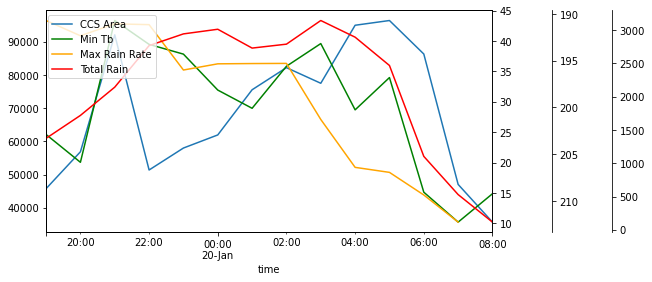

In [10]:
# The time series of the track indexed by time, so that the x axis is the time of each step
ts = track.set_index("time")

# --- Plot several variables of the track on their own y axes (the same matplotlib calls as in the Xarray demo) ---
fig, ax1 = plt.subplots(figsize=(8, 4))
ts["ccs_area"].plot(ax=ax1, label="CCS Area")

# Minimum Tb (axis inverted: colder is up)
ax2 = ax1.twinx()
ts["corecold_mintb"].plot(ax=ax2, color="green", label="Min Tb")
ax2.spines["right"].set_position(("outward", 60))
ax2.invert_yaxis()

# Maximum rain rate of the first (largest) precipitation feature: column pf_maxrainrate__0
ax3 = ax1.twinx()
ts["pf_maxrainrate__0"].plot(ax=ax3, color="orange", label="Max Rain Rate")

# Total rain
ax4 = ax1.twinx()
ts["total_rain"].plot(ax=ax4, color="red", label="Total Rain")
ax4.spines["right"].set_position(("outward", 120))

# One legend for all the axes, inside the plot (not over the extra y axes)
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.88))

### Merge / split fragments and the PF variables of a track

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| merge fragments | `track.merge_cloudnumber.values[:duration, :]` ([time, 50 slots], -9999 = none) | `fragments[(fragments["track"] == track_id) & (fragments["kind"] == 0)]`: **one row per fragment**, with `k`, `slot`, `cloudnumber`, `ccs_area` |
| split fragments | `track.split_cloudnumber.values[:duration, :]` | the same with `kind == 1` |
| the dense `[time, slot]` array back | (it is the dense array) | `.pivot(index="k", columns="slot", values="cloudnumber")` |
| PF variables | `track.pf_rainrate.values[:duration, :]` ([time, nmaxpf]) | `track.filter(like="pf_rainrate__")` (a DataFrame, one column per PF slot) |

In [11]:
# --- Merge and split fragments of the track: one row per fragment (time step k, slot, cloud number, area) ---
of_track = fragments[fragments["track"] == track_id]
merges = of_track[of_track["kind"] == 0]
splits = of_track[of_track["kind"] == 1]
display(merges.head(8))
print(f"{len(merges)} merge fragments, {len(splits)} split fragments")

# --- The [time, merger slot] array of the dense file, rebuilt with a pivot (NaN where there is no fragment) ---
merge_cloudnumber = merges.pivot(index="k", columns="slot", values="cloudnumber").reindex(range(duration))
display(merge_cloudnumber.head(8))

# --- The PF variables of the track: the columns pf_rainrate__0, pf_rainrate__1, pf_rainrate__2 (NaN where there is no such feature) ---
pf_rainrate = track.filter(like="pf_rainrate__")
display(pf_rainrate.head(8))

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    xr_track = dstracks.sel(tracks=track_id)
    xr_merge = xr_track.merge_cloudnumber.values[:duration, :]
    pivoted = merge_cloudnumber.reindex(columns=range(xr_merge.shape[1])).to_numpy()
    assert np.array_equal(pivoted, np.where(xr_merge == -9999, np.nan, xr_merge), equal_nan=True)
    assert np.array_equal(pf_rainrate.to_numpy(), xr_track.pf_rainrate.values[:duration, :], equal_nan=True)
    print("fragments and PF variables: same as Xarray")

,track,k,slot,cloudnumber,ccs_area,kind
67931,2001,0,0,127,42929.496094,0
67932,2001,1,0,129,39304.890625,0
67933,2001,7,0,639,2534.715820,0
67934,2001,8,0,600,2994.719971,0
67935,2001,8,1,397,5612.623047,0


5 merge fragments, 0 split fragments


slot,0,1
k,,
0,127.0,NaN
1,129.0,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,639.0,NaN


,pf_rainrate__0,pf_rainrate__1,pf_rainrate__2
38342,10.500865,3.126875,NaN
38343,9.022778,NaN,NaN
38344,9.504718,NaN,NaN
38345,9.106574,NaN,NaN
38346,8.736115,7.440909,NaN
38347,8.212215,NaN,NaN
38348,7.293750,NaN,NaN
38349,6.826283,NaN,NaN


fragments and PF variables: same as Xarray


### The track path

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| coordinates as arrays | `track.meanlon.values`, `track.meanlat.values` | `track["meanlon"].to_numpy()`, `track["meanlat"].to_numpy()` |
| first / last point | `track.meanlon.values[0]`, `track.meanlon.values[duration - 1]` | `track["meanlon"].iloc[0]`, `track["meanlon"].iloc[-1]` (no need for `duration`) |
| time step of the data | `dstracks.attrs["time_resolution_hour"]` | `attrs["time_resolution_hour"]` (from `meta.json`) |
| min / max for the map extent | `track.meanlon.min().item()` | `track["meanlon"].min()` |

`smooth_trajectory` takes arrays: the same call as in the Xarray demo.

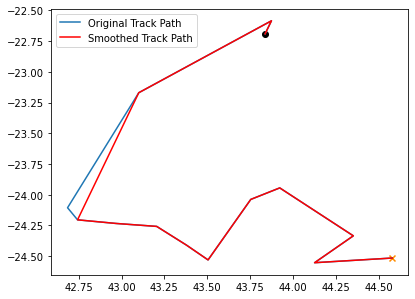

In [12]:
# The path of the track as numpy arrays (no NaN padding)
lon, lat = track["meanlon"].to_numpy(), track["meanlat"].to_numpy()

# Start point (circle) and end point (cross)
plt.scatter(lon[0], lat[0], marker="o", color="k")
plt.scatter(lon[-1], lat[-1], marker="x", color="darkorange")

# The path as tracked, and the smoothed path (the function and its arguments are those of the Xarray demo)
plt.plot(lon, lat, label="Original Track Path")
time_resolution = attrs["time_resolution_hour"]
max_speed_kmh = 100
lon_s, lat_s = smooth_trajectory(lon, lat, max_speed_kmh=max_speed_kmh, time_step_h=time_resolution)
plt.plot(lon_s, lat_s, color="red", label="Smoothed Track Path")
plt.legend()

### Cold cloud shield swath on a map

The function of the Xarray demo needs only the longitude, latitude and area of every time step: it takes them from a DataFrame instead of a Dataset
(`track.meanlon.values[i]` becomes `lon[i]` of `track["meanlon"].to_numpy()`; the loop over `range(duration)` becomes a loop over the rows).

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| loop over the time steps | `for i in range(duration): track.meanlon.values[i], track.ccs_area.values[i]` | `for lon_i, lat_i, area_i in zip(track["meanlon"], track["meanlat"], track["ccs_area"])` |
| map extent | `track.meanlon.min().item() - 20, ...` | `track["meanlon"].min() - 20, ...` |

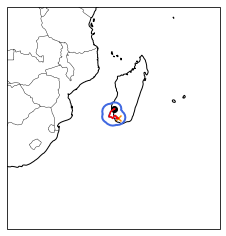

In [13]:
def add_ccs_area_swath(ax, track, n_points=20):
    """
    Add the swath of the cold cloud system to a map, treating each cold cloud shield as a circle of the same area (the Pandas version of the Xarray demo).

    Args:
        ax: cartopy GeoAxes
            Map axes (PlateCarree data coordinates).
        track: pandas.DataFrame
            The entries of one track, with the columns meanlon, meanlat and ccs_area [km^2].
        n_points: int (default: 20)
            Number of points of each circle.
    """
    try:
        # N.B. these are optional dependencies.
        import shapely.geometry
        import shapely.ops
    except ImportError:
        print("shapely not installed")
        return
    # One circle per time step, with the radius of a circle of the same area
    geoms = []
    for lon_i, lat_i, area_i in zip(track["meanlon"], track["meanlat"], track["ccs_area"]):
        radius = np.sqrt(area_i / np.pi) * 1e3
        circle_points = cartopy.geodesic.Geodesic().circle(lon=lon_i, lat=lat_i, radius=radius, n_samples=n_points, endpoint=False)
        geoms.append(shapely.geometry.Polygon(circle_points))
    # Combine all the circles into one swath
    ax.add_geometries((shapely.ops.unary_union(geoms),), crs=cartopy.crs.PlateCarree(), facecolor="none", edgecolor="royalblue", linewidth=2)


# A map with the track, its smoothed path and the swath of its cold cloud shield
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
fig.set_size_inches((8, 4))
ax.coastlines()
ax.add_feature(cf.BORDERS, linewidth=0.4)
ax.scatter(lon[0], lat[0], marker="o", color="k")
ax.scatter(lon[-1], lat[-1], marker="x", color="darkorange")
ax.plot(lon, lat)
ax.plot(lon_s, lat_s, color="red")
add_ccs_area_swath(ax, track)
ax.set_extent((track["meanlon"].min() - 20, track["meanlon"].max() + 20, track["meanlat"].min() - 20, track["meanlat"].max() + 20))

## Group properties of tracks

Here Pandas is at its best. In the dense file a group statistic reduces an array along the `times` axis *including the padding*, so you must remember to skip the NaN; in the row tables
a statistic of "the time steps of each track" is a `groupby("track")` of the rows that exist.

### Statistics of the per-track variables

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| mean duration | `dstracks.track_duration.mean().values.item()` (or `.values.mean()`) | `tracks["track_duration"].mean()` |
| mean duration of a selection | `dstracks_tropical.track_duration.values.mean()` | `tracks.loc[tropical_ids, "track_duration"].mean()` or `dstracks_tropical["track_duration"].mean()` |
| distribution | `dstracks.track_duration.values` + `np.percentile` | `tracks["track_duration"].describe()` (count, mean, std, quartiles) |

In [14]:
# Mean track duration of all tracks, and of the tropical tracks
mean_duration = tracks["track_duration"].mean()
mean_duration_tropical = dstracks_tropical["track_duration"].mean()
print(f"mean duration: {mean_duration:.3f} h, tropical: {mean_duration_tropical:.3f} h")

# A summary of the distribution in one call
display(tracks["track_duration"].describe())

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    assert np.isclose(dstracks.track_duration.mean().values.item(), mean_duration)
    assert np.isclose(dstracks.track_duration.sel(tracks=tropical_ids).values.mean(), mean_duration_tropical)
    print("durations: same as Xarray")

mean duration: 18.924 h, tropical: 18.409 h


count    41501.000000
mean        18.924363
std         12.931226
min          5.000000
25%         11.000000
50%         16.000000
75%         23.000000
max        296.000000
Name: track_duration, dtype: float64

durations: same as Xarray


### Mean of a lifetime variable for each track

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| mean over the lifetime | `np.nanmean(dstracks.ccs_area.values, axis=1)` or `dstracks.ccs_area.mean(dim="times", skipna=True)` | `entries.groupby("track")["ccs_area"].mean()` (NaN are skipped by default; one value per track, indexed by track number) |
| other reductions | `.max(dim="times")`, `.min`, `.sum`, `.std` | `.max()`, `.min()`, `.sum()`, `.std()` of the same groupby, or `.agg(["mean", "max"])` for several at once |
| histogram | `plt.hist(mean_areas, bins=...)` | `mean_areas.plot.hist(bins=...)` or `plt.hist(mean_areas, bins=...)` |

mean area per track: same as Xarray


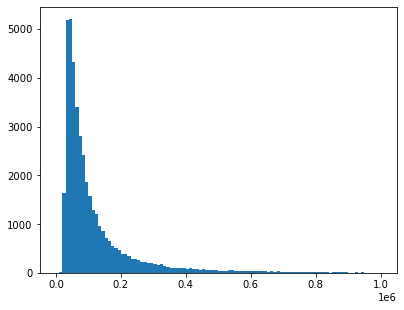

In [15]:
# Mean cold cloud shield area of each track over its life (one value per track)
mean_areas = entries.groupby("track")["ccs_area"].mean()

# Histogram of the mean areas
plt.hist(mean_areas, bins=np.linspace(0, 1e6, 101))

# --- Check against Xarray: the same values (float32 sums can differ in the last digit, so compare with a tolerance) ---
if CHECK_WITH_XARRAY:
    xr_mean_areas = dstracks.ccs_area.mean(dim="times", skipna=True).values
    assert np.allclose(mean_areas.reindex(dstracks.tracks.values).to_numpy(), xr_mean_areas, rtol=1e-5, equal_nan=True)
    assert np.allclose(np.nanmean(dstracks.ccs_area.values, axis=1), xr_mean_areas, equal_nan=True)
    print("mean area per track: same as Xarray")

## Linking tracks to the pixel-level data

Every track has a track number in the pixel-level files (`cloudtracknumber`): **the 0-based track index + 1**. The track's time stamps and track number are all you need from the statistics, and
they come out of the row tables directly. The rest of the section is the same as the Xarray demo; here it uses the lat/lon `mcstrack_*.nc` files of the IMERG run (the demo opens the HEALPix catalog).

| | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| tracks that started in a month, with a duration range | `dates = pd.DatetimeIndex(dstracks_tropical.start_basetime.values)`; `dstracks_tropical.isel(tracks=(dates.month == 6) & (dstracks_tropical.track_duration > 20) & ...)` | `dstracks_tropical[(dstracks_tropical["start_time"].dt.month == 6) & dstracks_tropical["track_duration"].between(21, 39)]` |
| the n-th selected track | `....isel(tracks=itrack)` | `selected.iloc[itrack]` (the row) and `selected.index[itrack]` (its track number) |
| the track's time stamps | `track.base_time.values[:duration]` + `convert_to_cftime(...)` for a model calendar | `track["time"]` (Timestamps, one per step; use `convert_to_cftime` of the demo for a `noleap` calendar) |
| the track number in the pixel files | `track.tracks + 1` | `track_id + 1` |

In [16]:
# --- Select a tropical track that started in June and lasted 21 to 39 hours (`start_time`, `track_duration` are columns of the tracks table) ---
selected = dstracks_tropical[(dstracks_tropical["start_time"].dt.month == 6) & dstracks_tropical["track_duration"].between(21, 39)]
print(f"{len(selected)} tropical tracks started in June and lasted 21 - 39 h")

# The n-th of them: its row of per-track variables, its track number, and its time series
itrack = 2
track_row = selected.iloc[itrack]
track_id = selected.index[itrack]
track = entries_of(track_id)
duration = track_row["track_duration"]
print(f"track {track_id}, duration {duration} h, started {track_row['start_time']}")

# --- Check against Xarray ---
if CHECK_WITH_XARRAY:
    xr_tropical = dstracks.sel(tracks=tropical_ids)
    dates = pd.DatetimeIndex(xr_tropical.start_basetime.dt.round("s").values)
    in_range = (xr_tropical.track_duration.values > 20) & (xr_tropical.track_duration.values < 40)
    xr_selected = xr_tropical.isel(tracks=(dates.month == 6) & in_range)
    assert np.array_equal(xr_selected.tracks.values, selected.index.values)
    print("selection: same as Xarray")

651 tropical tracks started in June and lasted 21 - 39 h
track 17064, duration 34 h, started 2019-06-01 03:00:00


selection: same as Xarray


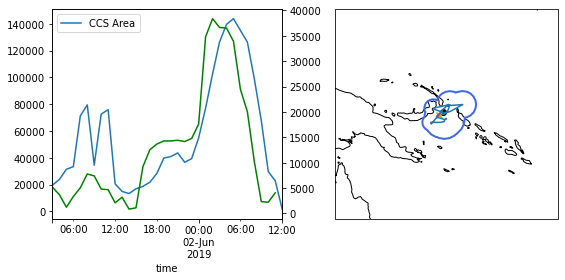

In [17]:
# --- Two panels: the area time series (left) and the path with the swath on a map (right) ---
fig = plt.figure(figsize=(8, 4))

# Left: the cold cloud shield area and the area of the largest precipitation feature (column pf_area__0)
ax1 = fig.add_subplot(1, 2, 1)
ts = track.set_index("time")
ts["ccs_area"].plot(ax=ax1, label="CCS Area")
ax1b = ax1.twinx()
ts["pf_area__0"].plot(ax=ax1b, color="green", label="PF Area")
ax1.legend()

# Right: the track on a map
ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
ax2.coastlines()
ax2.add_feature(cf.BORDERS, linewidth=0.4)
ax2.scatter(track["meanlon"].iloc[0], track["meanlat"].iloc[0], marker="o", color="k")
ax2.scatter(track["meanlon"].iloc[-1], track["meanlat"].iloc[-1], marker="x", color="darkorange")
ax2.plot(track["meanlon"], track["meanlat"])
add_ccs_area_swath(ax2, track)
buffer = 10
ax2.set_extent((track["meanlon"].min() - buffer, track["meanlon"].max() + buffer, track["meanlat"].min() - buffer, track["meanlat"].max() + buffer))
fig.tight_layout()

### Time stamps and track number for the pixel-level files

```python
# The Xarray demo, for the HEALPix catalog (needs the SCREAM data; the lines that differ from this notebook are the first two)
calendar = ds["time"].dt.calendar
base_times = track.base_time.values[:duration]                                   # Pandas: track["time"]
track_dates = [convert_to_cftime(pd.Timestamp(d).to_pydatetime(), calendar) for d in base_times]
track_number = track.tracks + 1                                                  # Pandas: track_id + 1
_ds = ds.sel(time=track_dates[i], method="nearest")                              # unchanged
_mask = _ds.mcs_mask.load().where(_ds.mcs_mask == track_number, 1, 0)           # unchanged
```

In [18]:
# The time stamps of the track (one per step) and its track number in the pixel-level files
track_dates = list(track["time"])
track_number = track_id + 1
print(f"{len(track_dates)} time steps from {track_dates[0]} to {track_dates[-1]}; track number in the pixel files: {track_number}")

34 time steps from 2019-06-01 03:00:00 to 2019-06-02 12:00:00; track number in the pixel files: 17065


### Four frames of the track in the pixel-level files

The pixel-level file of an hour is `mcstrack_YYYYMMDD_hhmmss.nc`; its `cloudtracknumber` is the track number inside the cold cloud shield of every MCS, `precipitation` is the rain rate and `tb` the
brightness temperature. The mask of this track is `cloudtracknumber == track_number`. (The Xarray demo makes an animation of every frame; a few static frames show the same link.)

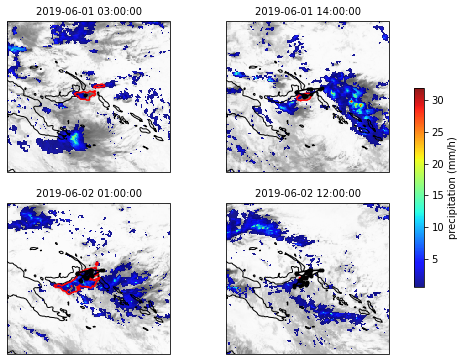

In [19]:
def pixel_file(time_stamp):
    """
    Name of the pixel-level file of a time.

    Args:
        time_stamp: pandas.Timestamp
            Time of the file (a track time stamp).

    Returns:
        path: string
            PIXEL_DIR/mcstrack_YYYYMMDD_hhmmss.nc
    """
    return f"{PIXEL_DIR}/mcstrack_{time_stamp:%Y%m%d_%H%M%S}.nc"


# Four frames evenly spaced over the life of the track
frames = np.linspace(0, len(track_dates) - 1, 4).astype(int)

# The map window around the track
margin = 8
window = dict(lat=slice(track["meanlat"].min() - margin, track["meanlat"].max() + margin),
              lon=slice(track["meanlon"].min() - margin, track["meanlon"].max() + margin))

# --- Draw the frames: Tb (gray), precipitation (color), the mask of the track (red contour) and the track path so far ---
fig, axes = plt.subplots(2, 2, figsize=(9, 6), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, i in zip(axes.ravel(), frames):
    # The pixel-level file of this time step, cut to the window
    px = xr.open_dataset(pixel_file(track_dates[i])).isel(time=0).sel(**window)
    # The mask of this track: the pixels whose track number is the track number of the statistics
    mask = (px["cloudtracknumber"] == track_number)
    assert int(mask.sum()) > 0, "the track has no pixels in the file"
    # Tb in gray, rain rates above 0.5 mm/h in color, the mask as a contour
    ax.pcolormesh(px["lon"], px["lat"], px["tb"], cmap="Greys_r", vmin=190, vmax=300, alpha=0.8)
    pr = px["precipitation"].where(px["precipitation"] >= 0.5)
    im = ax.pcolormesh(px["lon"], px["lat"], pr, cmap="jet", vmin=0.5, vmax=32, alpha=0.9)
    ax.contour(px["lon"], px["lat"], mask.astype(int), levels=[0.5], colors="red", linewidths=1.5)
    # The track so far
    ax.plot(track["meanlon"].iloc[:i + 1], track["meanlat"].iloc[:i + 1], color="k", marker="o", markersize=3)
    ax.coastlines()
    ax.set_title(f"{track_dates[i]}", fontsize=10)
    px.close()
fig.colorbar(im, ax=axes, shrink=0.6, label="precipitation (mm/h)")

* Track: black line with circles at the centroid of each hour.
* MCS mask of this track: red contour.
* Tb: gray; precipitation: color.

## Beyond the demo: what rows make easy

The operations below are one line with the row tables; with the dense file each one needs a loop, a mask over the padding or a reduction with care for the NaN.

| task | Xarray (dense file) | Pandas (row tables) |
|---|---|---|
| a summary table, one row per track | one `.max(dim="times")` / `.mean(...)` per variable, then `xr.merge` | `entries.groupby("track").agg(max_area=("ccs_area", "max"), mean_rain=("total_rain", "mean"))` |
| the entry where a variable peaks | `idxmax(dim="times")` and `take_along_axis` for the other variables | `entries.loc[entries.groupby("track")["ccs_area"].idxmax()]` |
| MCS counts per month | a loop, or `groupby("start_basetime.month")` after decoding | `tracks.groupby(tracks["start_time"].dt.month).size()` |
| a diurnal cycle | build a time mask over the padded array | `entries.groupby(entries["time"].dt.hour)["ccs_area"].mean()` |
| join with other per-MCS tables (e.g. the trackpcp metrics) | align by hand on the track number | `tracks.join(other)` / `pd.merge(..., left_index=True, right_on=...)` |

,track_duration,start_time,max_ccs_area,mean_total_rain,min_tb
tracks,,,,,
0,34,2019-01-01,2.404062e+06,25532.345703,181.107712
1,60,2019-01-01,1.137879e+06,7806.080566,209.260300
2,22,2019-01-01,1.036460e+06,10996.223633,211.064896
3,23,2019-01-01,1.371025e+06,18343.277344,212.823502
4,42,2019-01-01,2.639010e+06,34921.062500,174.280258


41501 peak entries; median time of the peak after the start: 8.0 h


start_time,1,2,3,4,5,6,7,8,9,10,11,12
MCS started,3336,2824,3627,3533,3729,3629,3590,3468,3330,3832,3311,3292


<Axes: xlabel='hour (UTC)', ylabel='mean CCS area (km$^2$)'>

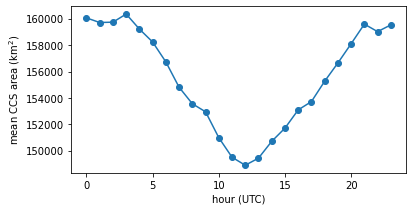

In [20]:
# --- One row per track: statistics of the lifetime variables next to the per-track variables ---
summary = entries.groupby("track").agg(max_ccs_area=("ccs_area", "max"), mean_total_rain=("total_rain", "mean"), min_tb=("corecold_mintb", "min"))
summary = tracks[["track_duration", "start_time"]].join(summary)
display(summary.head())

# --- The entry at which the cold cloud shield is largest, for every track (all the other variables come with it) ---
at_peak = entries.loc[entries.groupby("track")["ccs_area"].idxmax()]
print(f"{len(at_peak)} peak entries; median time of the peak after the start: {np.median(at_peak['k'])} h")

# --- Number of MCS that started in each month ---
display(tracks.groupby(tracks["start_time"].dt.month).size().rename("MCS started").to_frame().T)

# --- Diurnal cycle of the cold cloud shield area: the hour of the day of every entry (UTC) ---
diurnal = entries.groupby(entries["time"].dt.hour)["ccs_area"].mean()
diurnal.plot(marker="o", figsize=(6, 3), xlabel="hour (UTC)", ylabel="mean CCS area (km$^2$)")

### Move between the two worlds

| | |
|---|---|
| rows to Xarray (a few tracks or variables) | `from pyflextrkr.rowstats import load_trackstats`; `load_trackstats(rows, tracks=ids, variables=["ccs_area"])` |
| rows to a dense `Dataset` by hand | `entries.set_index(["track", "k"])[["ccs_area"]].to_xarray()` (a `[track, k]` array, NaN where a track is shorter) |
| Xarray to rows | `dstracks.ccs_area.to_dataframe().dropna()` (or the converter `dense_to_rows`) |
| rows to a dense netCDF file | `from pyflextrkr.rowstats import write_dense_netcdf` (see [tbpf_mcs_workflow.md](../docs/tbpf_mcs_workflow.md)) |

In [21]:
# --- Rows to a dense Xarray array by hand: (track, k) becomes a two-dimensional index, unstacked into [tracks, times] ---
subset = entries[entries["track"] < 5]
dense = subset.set_index(["track", "k"])["ccs_area"].to_xarray()
print(dense.sizes)

# --- The same with the built-in function (it restores the dimension names, dtypes and fill values of the dense file) ---
from pyflextrkr.rowstats import load_trackstats

ds_small = load_trackstats(ROWS, tracks=np.arange(5), variables=["ccs_area"], fragments=False)
print(dict(ds_small.sizes))

Frozen({'track': 5, 'k': 60})


{'tracks': 5, 'times': 60, 'nmaxpf': 3, 'mergers': 50}


## How much faster is it?

The same questions answered from the dense file with Xarray and from the row tables with Pandas on this year, in two parts: **reading** the variables the questions need (Pandas reads only those
columns of the Parquet file; Xarray reads the padded arrays of the dense file), then **answering** the questions on the data in memory. The times depend on the file system and on whether the files
are cached: run it twice.

In [22]:
def timed(func):
    """
    Wall-clock time of calling a function once.

    Args:
        func: callable
            Function without arguments.

    Returns:
        seconds, result: float, the return value of func
    """
    t0 = time.perf_counter()
    result = func()
    return time.perf_counter() - t0, result


def read_rows():
    """The columns of the entries table that the questions need, with the time converted (Pandas)."""
    df = pd.read_parquet(f"{ROWS}/entries.parquet", columns=["track", "base_time", "meanlat", "ccs_area"])
    df["time"] = seconds_to_time(df["base_time"])
    return df


def read_dense():
    """The variables that the questions need, loaded from the dense file (Xarray)."""
    return xr.open_dataset(NC, mask_and_scale=True)[["base_time", "meanlat", "ccs_area"]].load()


# --- Pandas on the row tables: read the columns, then answer the questions on the DataFrame in memory ---
seconds, small = timed(read_rows)
pandas_times = {"read ccs_area, base_time, meanlat": seconds}
pandas_questions = {
    "mean CCS area of every track": lambda: small.groupby("track")["ccs_area"].mean(),
    "max CCS area of every track": lambda: small.groupby("track")["ccs_area"].max(),
    "tracks active at one time": lambda: small.loc[small["time"] == datetime, "track"].unique(),
    "tracks with a step in the tropics": lambda: small.loc[small["meanlat"].between(-20, 20, inclusive="neither"), "track"].unique(),
}
for name, question in pandas_questions.items():
    pandas_times[name], _ = timed(question)
result = pd.DataFrame({"Pandas, row tables [s]": pandas_times})

# --- Xarray on the dense file: load the arrays, then answer the same questions on the Dataset in memory ---
if CHECK_WITH_XARRAY:
    seconds, loaded = timed(read_dense)
    xarray_times = {"read ccs_area, base_time, meanlat": seconds}
    xarray_questions = {
        "mean CCS area of every track": lambda: loaded.ccs_area.mean(dim="times", skipna=True).values,
        "max CCS area of every track": lambda: loaded.ccs_area.max(dim="times", skipna=True).values,
        "tracks active at one time": lambda: (loaded.base_time.values == datetime.to_datetime64()).any(axis=1),
        "tracks with a step in the tropics": lambda: ((loaded.meanlat.values > -20) & (loaded.meanlat.values < 20)).any(axis=1),
    }
    for name, question in xarray_questions.items():
        xarray_times[name], _ = timed(question)
    result["Xarray, dense file [s]"] = pd.Series(xarray_times)
    result["Xarray / Pandas"] = result["Xarray, dense file [s]"] / result["Pandas, row tables [s]"]
display(result.round(3))

# --- The memory of the variables that the questions needed ---
print(f"memory of ccs_area, base_time, meanlat, track, time: Pandas {small.memory_usage(deep=True).sum() / 1e9:.3f} GB"
      + (f", Xarray (dense) {loaded.nbytes / 1e9:.3f} GB" if CHECK_WITH_XARRAY else ""))

,"Pandas, row tables [s]","Xarray, dense file [s]",Xarray / Pandas
"read ccs_area, base_time, meanlat",0.097,1.732,17.900
mean CCS area of every track,0.010,0.011,1.078
max CCS area of every track,0.009,0.011,1.250
tracks active at one time,0.002,0.017,10.747
tracks with a step in the tropics,0.004,0.008,1.977


memory of ccs_area, base_time, meanlat, track, time: Pandas 0.022 GB, Xarray (dense) 0.266 GB


**What the table says.** *Reading* is where rows win: the row tables hold only the entries that exist, and Pandas reads only the columns that are asked for. *Answering* a plain reduction along time on
data that is already in memory takes about the same time, because Xarray hands numpy the same numbers (the dense comparison of 'tracks active at one time' touches ten times more cells, the NaN padding).
*Memory* is the other half: the line under the table is for the three variables, and the whole file is 26 GB dense against 0.33 GB of tables (printed at the top). With the
dense file a year needs a big-memory node or Dask; with the row tables a laptop will do, and a question that is not a reduction along `times` (a join, a group by month, a filter on several variables) stays
one line.

## Where to go from here

* [docs/rowstats_pandas.md](../docs/rowstats_pandas.md): the cheat sheet (every command of this notebook next to its Xarray form), how to read the files fast, joins, pitfalls.
* [docs/rowstats.md](../docs/rowstats.md): the format of the row tables and the other ways to read them (`load_trackstats`, `RowStats`).
* [docs/tbpf_mcs_workflow.md](../docs/tbpf_mcs_workflow.md): how the files are made, and how to write the dense netCDF file of any statistics file.